# Hierarchical states

Node states can be any hashable value, including tuples, which are a natural way to represent a state with several parts.
This notebook uses a 2-tuple, `(cell_type, k)`, to combine a cell's type in a differentiation hierarchy with its progress through the cell cycle.

Splitting the cell cycle into stages controls the distribution of generation times, which would otherwise be exponential.
With few stages, generation times vary widely and lineages quickly fall out of step; with many stages, generation times are nearly constant and divisions stay synchronized.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats
from matplotlib.patches import Patch

import bdms

## Model

Cells are progenitors, intermediates, or terminal cells.
The state of a dividing cell is `(cell_type, k)`, where `k = 0, 1, ..., K - 1` is its stage in the cell cycle.

- **Cell-cycle progression:** a cell in stage `k < K - 1` moves to stage `k + 1` at rate `K / T_gen`. In BDMS, these are mutation events.
- **Division:** only cells in the last stage, `K - 1`, divide, also at rate `K / T_gen`. A full cycle is then `K` exponential stages, each with mean `T_gen / K`, so generation times have a gamma (Erlang) distribution with mean `T_gen` and standard deviation `T_gen / sqrt(K)`. With `K = 1`, this is a birth process with exponential generation times.
- **Differentiation:** each daughter cell starts a new cycle at stage 0, and may take a new cell type: daughters of progenitors can become intermediates, and daughters of intermediates can become terminal cells. Setting `birth_mutation_prob=1.0` gives every daughter a mutation event at birth, which applies this change.
- **Terminal cells** don't divide, so they have a single state, `("terminal", 0)`.
- **Death** happens at a constant rate for each cell type, highest for intermediates.

These are the parameters:

In [2]:
K = 100  # number of cell-cycle stages
T_gen = 1.0  # mean generation time
dividing_types = ("progenitor", "intermediate")
# probability that each daughter of a dividing cell has each cell type
fate_probs = {
    "progenitor": {"progenitor": 0.75, "intermediate": 0.25},
    "intermediate": {"intermediate": 0.5, "terminal": 0.5},
}
death_rates = {"progenitor": 0.05, "intermediate": 0.5, "terminal": 0.2}

Next, we build the Poisson processes and the mutator as `bdms` API objects.
The mutator's transition matrix describes both kinds of state change: from a stage `k < K - 1` it moves to stage `k + 1`, and from the last stage it applies the daughter cell-type probabilities.

In [3]:
states = [(cell_type, k) for cell_type in dividing_types for k in range(K)]
states.append(("terminal", 0))
index = {state: i for i, state in enumerate(states)}
stage_rate = K / T_gen

birth_rates = {}
progression_rates = {}
transition_matrix = np.zeros((len(states), len(states)))
for state in states:
    cell_type, k = state
    i = index[state]
    if cell_type == "terminal":
        # terminal cells neither progress nor divide
        birth_rates[state] = 0.0
        progression_rates[state] = 0.0
        transition_matrix[i, i] = 1.0  # never used
    elif k < K - 1:
        # move to the next stage
        birth_rates[state] = 0.0
        progression_rates[state] = stage_rate
        transition_matrix[i, index[(cell_type, k + 1)]] = 1.0
    else:
        # divide, and each daughter starts a new cycle, maybe as another type
        birth_rates[state] = stage_rate
        progression_rates[state] = 0.0
        for daughter_type, prob in fate_probs[cell_type].items():
            transition_matrix[i, index[(daughter_type, 0)]] = prob

birth_process = bdms.poisson.DiscreteProcess(birth_rates)
death_process = bdms.poisson.DiscreteProcess(
    {state: death_rates[state[0]] for state in states}
)
# mutation events move cells through the cell cycle
mutation_process = bdms.poisson.DiscreteProcess(progression_rates)
mutator = bdms.mutators.DiscreteMutator(states, transition_matrix)

## Generation times

As the number of stages grows, the generation-time distribution narrows around its mean, `T_gen` (dashed line).
We use `K = 100` stages:

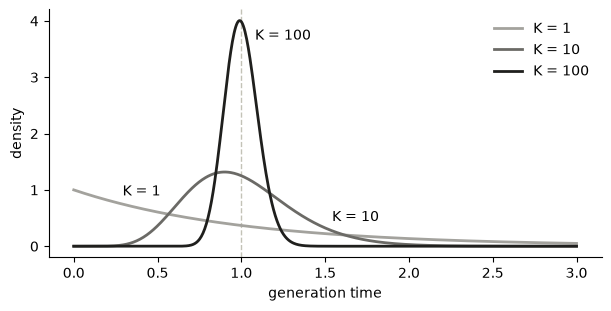

In [4]:
reference = "#c3c2b7"  # color for reference lines
# light to dark for increasing numbers of stages
K_colors = {1: "#a3a29d", 10: "#6b6a66", 100: "#1f1f1d"}
# where to label each curve, away from the other curves
label_times = {1: 0.25, 10: 1.5, 100: 1.04}

t = np.linspace(0, 3 * T_gen, 600)
fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
for K_example, color in K_colors.items():
    gamma = scipy.stats.gamma(a=K_example, scale=T_gen / K_example)
    ax.plot(t, gamma.pdf(t), color=color, lw=2, label=f"K = {K_example}")
    label_time = label_times[K_example] * T_gen
    ax.annotate(
        f"K = {K_example}",
        xy=(label_time, gamma.pdf(label_time)),
        xytext=(5, 5),
        textcoords="offset points",
    )
ax.axvline(T_gen, color=reference, lw=1, ls="--", zorder=0)
ax.set_xlabel("generation time")
ax.set_ylabel("density")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Simulation

Simulate a tree starting from one progenitor at the start of its cycle, for 10 mean generation times:

In [5]:
tree = bdms.Tree(state=("progenitor", 0))
tree.evolve(
    10 * T_gen,
    birth_process=birth_process,
    death_process=death_process,
    mutation_process=mutation_process,
    mutator=mutator,
    birth_mutation_prob=1.0,
    seed=1,
)
divisions = sum(node.event == "birth" for node in tree.traverse())
alive = [leaf.state[0] for leaf in tree if leaf.event == "survival"]
counts = ", ".join(
    f"{cell_type} {alive.count(cell_type)}"
    for cell_type in ("progenitor", "intermediate", "terminal")
)
print(f"{divisions} divisions; cells alive at the end: {counts}")

87 divisions; cells alive at the end: progenitor 30, intermediate 17, terminal 12


## Rendering

We'll color the tree by cell type.
`Tree.render` colors branches using a map from state values to colors, so we map each `(cell_type, k)` state to the color of its cell type.
These are the colors:

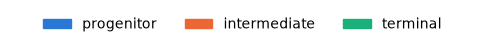

In [6]:
colors = {"progenitor": "#2a78d6", "intermediate": "#eb6834", "terminal": "#1baf7a"}

fig, ax = plt.subplots(figsize=(6, 0.4))
ax.legend(
    handles=[Patch(color=color, label=label) for label, color in colors.items()],
    ncol=len(colors),
    loc="center",
    frameon=False,
)
ax.axis("off")
plt.show()

Time runs down the page.
Dashed branches are lineages that died out.
Intermediate cells, in orange, have the highest death rate.
Divisions happen in nearly synchronized waves, about one mean generation time apart:

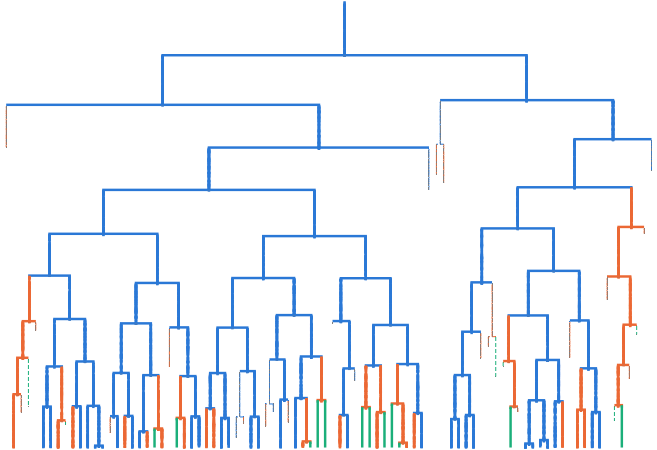

In [7]:
color_map = {state: colors[state[0]] for state in states}
tree.render("%%inline", color_map=color_map, h=5, units="in")

## Synchronization

To see synchronization over many trees, we pool the division times from 200 simulations, up to time 5.
Setting `min_survivors=0` keeps simulations in which every cell dies, so the sample isn't limited to populations that survive.

Divisions cluster around multiples of `T_gen` (dashed lines).
The clusters spread out over time, because the time of the `n`th division in a lineage is a sum of `n` generation times, with standard deviation `T_gen * sqrt(n / K)`:

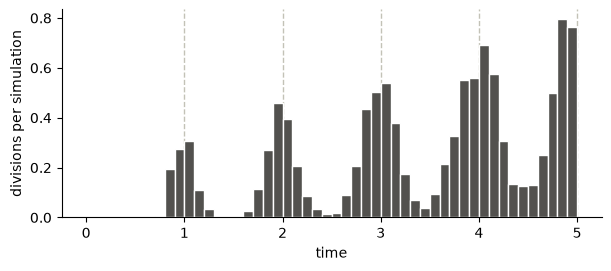

In [8]:
t_end = 5 * T_gen
n_simulations = 200
rng = np.random.default_rng(0)
division_times = []
for _ in range(n_simulations):
    tree = bdms.Tree(state=("progenitor", 0))
    tree.evolve(
        t_end,
        birth_process=birth_process,
        death_process=death_process,
        mutation_process=mutation_process,
        mutator=mutator,
        birth_mutation_prob=1.0,
        min_survivors=0,
        seed=rng,
    )
    division_times.extend(node.t for node in tree.traverse() if node.event == "birth")

fig, ax = plt.subplots(figsize=(6, 2.6), layout="constrained")
ax.hist(
    division_times,
    bins=np.arange(0, t_end + 1e-9, T_gen / 10),
    weights=np.full(len(division_times), 1 / n_simulations),
    color="#52514e",
    ec="white",
    lw=1,
)
for n in range(1, round(t_end / T_gen) + 1):
    ax.axvline(n * T_gen, color=reference, lw=1, ls="--", zorder=0)
ax.set_xlabel("time")
ax.set_ylabel("divisions per simulation")
ax.spines[["top", "right"]].set_visible(False)
plt.show()